<a href="https://colab.research.google.com/github/Reina-creator/MSSP607-GitHub/blob/main/WeeklyModules/Week08/Assignment8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving InternetSales.csv to InternetSales.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_name = next(name for name in uploaded if name.lower().endswith(".csv"))

sales = pd.read_csv(
    file_name,
    encoding="latin1",
    usecols=["OrderDate", "EnglishProductName", "SalesAmount"]
)

sales["OrderDate"] = pd.to_datetime(sales["OrderDate"])
sales["Year"] = sales["OrderDate"].dt.year

sales.head()

,EnglishProductName,SalesAmount,OrderDate,Year
0,"Mountain-100 Silver, 38",3399.99,2011-01-19,2011
1,"Mountain-200 Silver, 38",2319.99,2013-01-18,2013
2,Fender Set - Mountain,21.98,2013-01-18,2013
3,"Touring-1000 Blue, 46",2384.07,2013-05-03,2013
4,Touring Tire,28.99,2013-05-03,2013


In [4]:
annual_sales = (
    sales[sales["Year"].between(2011, 2013)]
    .groupby("Year")["SalesAmount"]
    .sum()
)

print("Historical annual sales:")
print(annual_sales)

Historical annual sales:
Year
2011    7.075526e+06
2012    5.842485e+06
2013    1.635155e+07
Name: SalesAmount, dtype: float64


In [5]:
slope, intercept = np.polyfit(
    annual_sales.index.to_numpy(),
    annual_sales.to_numpy(),
    1
)

future_years = np.arange(2014, 2019)
forecast_sales = np.maximum(slope * future_years + intercept, 0)

forecast = pd.DataFrame({
    "Year": future_years,
    "Forecast Sales": forecast_sales
})

print(forecast.to_string(index=False))

 Year  Forecast Sales
 2014    1.903254e+07
 2015    2.367056e+07
 2016    2.830857e+07
 2017    3.294658e+07
 2018    3.758459e+07


In [6]:
product_summary = (
    sales[sales["Year"].between(2011, 2013)]
    .groupby("EnglishProductName")["SalesAmount"]
    .agg(number_of_sales="count", total_sales="sum", average_sale="mean")
    .sort_values("total_sales", ascending=False)
)

print(product_summary.head(10))
print("\nProduct with the highest historical total sales:")
print(product_summary.index[0])

                         number_of_sales   total_sales  average_sale
EnglishProductName                                                  
Mountain-200 Black, 46               620  1.373470e+06   2215.273465
Mountain-200 Black, 42               614  1.363142e+06   2220.101129
Mountain-200 Silver, 38              596  1.339463e+06   2247.420789
Mountain-200 Silver, 46              580  1.301100e+06   2243.276032
Mountain-200 Black, 38               582  1.294866e+06   2224.855913
Mountain-200 Silver, 42              560  1.257435e+06   2245.418880
Road-150 Red, 48                     335  1.198720e+06   3578.270000
Road-150 Red, 62                     334  1.195142e+06   3578.270000
Road-150 Red, 52                     301  1.077059e+06   3578.270000
Road-150 Red, 56                     294  1.052011e+06   3578.270000

Product with the highest historical total sales:
Mountain-200 Black, 46


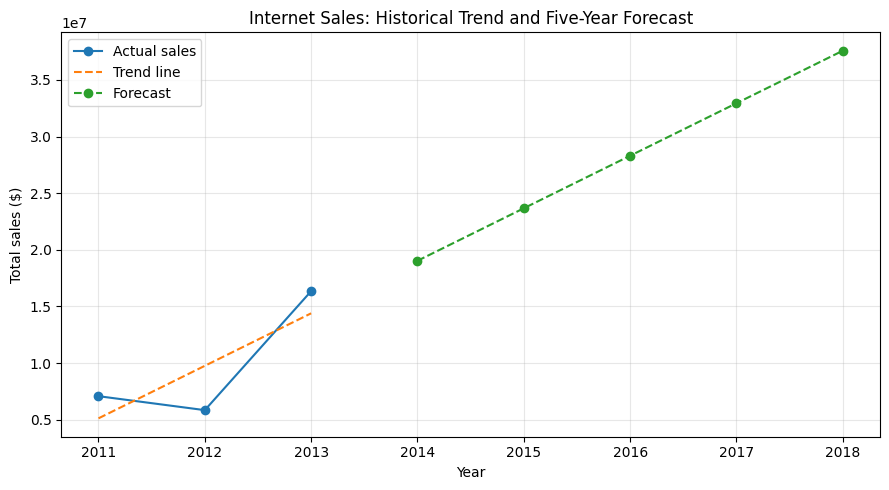

In [7]:
historical_trend = slope * annual_sales.index.to_numpy() + intercept

plt.figure(figsize=(9, 5))
plt.plot(annual_sales.index, annual_sales.values, "o-", label="Actual sales")
plt.plot(annual_sales.index, historical_trend, "--", label="Trend line")
plt.plot(future_years, forecast_sales, "o--", label="Forecast")

plt.title("Internet Sales: Historical Trend and Five-Year Forecast")
plt.xlabel("Year")
plt.ylabel("Total sales ($)")
plt.xticks(np.arange(2011, 2019))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()